# Parte 2 · Apartado 4: evaluación de FGSM en MNIST

**Objetivo del enunciado:** generar imágenes adversarias mediante la función FGSM creada en el apartado 3, predecirlas con **la CNN** y **la SVM RBF**, y visualizar las originales y las adversarias.

Además, compararemos diferentes valores de `epsilon` para justificar la elección y calcular la precisión de ambos modelos.

**Importante:** los ataques se generan **contra la CNN**, con las etiquetas verdaderas. Al pasarlos por la SVM medimos *transferencia del ataque*, no un FGSM optimizado contra la SVM. No utilizamos librerías de ataques adversarios.

## 0. Configuración

- **Modo rápido:** 1000 imágenes para revisar que funciona.
- **Modo completo:** 10000 imágenes para las tablas y gráficas definitivas.
- Solo se cargan modelos guardados: **no se reentrena nada**.
- Los píxeles están normalizados a `[0,1]`; `epsilon` está en esa escala.

Ejecuta el notebook desde la carpeta `io_parte2`. Cambia `MODO` a `"completo"` cuando el modo rápido funcione.

In [8]:
from pathlib import Path
import random
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from IPython.display import display

from entrenar_cnn import CNNMNIST
from fgsm import ataque_fgsm

SEMILLA = 42
MODO = "completo"            # "rapido" = 1000 imágenes | "completo" = 10000
LOTE = 128
EPSILONS = [0.0, 0.025, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]

CARPETA = Path.cwd().resolve()
CARPETA_SALIDAS = CARPETA / "resultados"
CARPETA_SALIDAS.mkdir(parents=True, exist_ok=True)

random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

dispositivo = torch.device("cpu")
print(f"Carpeta: {CARPETA}")
print(f"Modo: {MODO}; dispositivo: {dispositivo}")


Carpeta: /home/laura/proyectos/io_parte2
Modo: completo; dispositivo: cpu


## 1. Cargar los modelos y el test de MNIST

La CNN y la SVM reciben exactamente los mismos ejemplos de test. La CNN usa tensores de forma `(lote,1,28,28)` y la SVM recibe esos píxeles aplanados `(lote,784)`.

In [9]:
ruta_cnn = CARPETA / "cnn_mnist.pth"
ruta_svm = CARPETA / "svm_rbf_mnist.joblib"
for ruta in [ruta_cnn, ruta_svm]:
    if not ruta.is_file():
        raise FileNotFoundError(f"Falta {ruta}. Coloca este notebook junto a los modelos guardados.")

cnn = CNNMNIST().to(dispositivo)
cnn.load_state_dict(torch.load(ruta_cnn, map_location=dispositivo, weights_only=True))
cnn.eval()

# joblib debe cargar exclusivamente archivos creados por nosotros o de confianza.
svm = joblib.load(ruta_svm)

mnist_test = datasets.MNIST(
    root=CARPETA / "datos", train=False, download=True,
    transform=transforms.ToTensor()
)

if MODO == "rapido":
    indices = np.random.default_rng(SEMILLA).choice(len(mnist_test), 1000, replace=False)
    indices = np.sort(indices).tolist()
elif MODO == "completo":
    indices = list(range(len(mnist_test)))
else:
    raise ValueError("MODO debe ser 'rapido' o 'completo'")

subconjunto = Subset(mnist_test, indices)
cargador = DataLoader(subconjunto, batch_size=LOTE, shuffle=False, num_workers=0)
N = len(subconjunto)
print(f"Test disponible: {len(mnist_test)} | imágenes evaluadas: {N}")
print(f"Total de parámetros CNN: {sum(p.numel() for p in cnn.parameters()):,}")
print(f"Vectores de soporte SVM: {len(svm.support_):,}")


Test disponible: 10000 | imágenes evaluadas: 10000
Total de parámetros CNN: 105,866
Vectores de soporte SVM: 4,324


## 2. Prueba con varios epsilons: CNN y transferencia a SVM

Para cada imagen:

1. Generamos FGSM usando **la CNN y la etiqueta real**.
2. Clasificamos tanto la original como la adversaria con **ambos modelos**.
3. Registramos la precisión adversaria y la proporción de ataques exitosos **entre las imágenes que la CNN clasificaba correctamente antes del ataque**.

La **tasa de éxito FGSM** es una medida condicionada a aciertos iniciales, no el porcentaje de cambios sobre cualquier imagen. También medimos el cambio de predicción en SVM para estudiar transferencia.

Guardamos una tabla CSV por modo y una gráfica. En la evaluación completa pueden tardar las predicciones de SVM en CPU.

In [10]:
def evaluar_epsilon(epsilon, cargador, cnn, svm):
    """Evalúa el FGSM generado contra la CNN y su transferencia a la SVM."""
    totales = {k: 0 for k in [
        "n", "cnn_original", "cnn_adv", "svm_original", "svm_adv",
        "cnn_correctas_iniciales", "cnn_enganyadas",
        "svm_correctas_iniciales", "svm_enganyadas", "cambios_cnn", "cambios_svm"
    ]}
    perturbacion_maxima = 0.0
    inicio = time.perf_counter()

    for x, y in cargador:
        x, y = x.to(dispositivo), y.to(dispositivo)
        # El ataque requiere gradientes; no debemos envolver esta instrucción en no_grad.
        x_adv = ataque_fgsm(cnn, x, y, epsilon)

        # Verificamos que la perturbación cumple la cota L-infinito y que los píxeles son válidos.
        diferencia = (x_adv - x).abs().max().item()
        perturbacion_maxima = max(perturbacion_maxima, diferencia)
        assert diferencia <= epsilon + 1e-6
        assert x_adv.min().item() >= 0 and x_adv.max().item() <= 1

        with torch.no_grad():
            pred_cnn = cnn(x).argmax(dim=1).cpu().numpy()
            pred_cnn_adv = cnn(x_adv).argmax(dim=1).cpu().numpy()

        # SVC opera sobre un vector de 784 píxeles. Los mismos píxeles, sin normalización extra.
        pred_svm = svm.predict(x.cpu().numpy().reshape(len(x), 784))
        pred_svm_adv = svm.predict(x_adv.cpu().numpy().reshape(len(x), 784))
        reales = y.cpu().numpy()

        bien_cnn = pred_cnn == reales
        bien_svm = pred_svm == reales
        totales["n"] += len(reales)
        totales["cnn_original"] += int(bien_cnn.sum())
        totales["cnn_adv"] += int((pred_cnn_adv == reales).sum())
        totales["svm_original"] += int(bien_svm.sum())
        totales["svm_adv"] += int((pred_svm_adv == reales).sum())
        totales["cnn_correctas_iniciales"] += int(bien_cnn.sum())
        totales["cnn_enganyadas"] += int((bien_cnn & (pred_cnn_adv != reales)).sum())
        totales["svm_correctas_iniciales"] += int(bien_svm.sum())
        totales["svm_enganyadas"] += int((bien_svm & (pred_svm_adv != reales)).sum())
        totales["cambios_cnn"] += int((pred_cnn_adv != pred_cnn).sum())
        totales["cambios_svm"] += int((pred_svm_adv != pred_svm).sum())

    n = totales["n"]
    return {
        "epsilon": epsilon,
        "n": n,
        "cnn_original_pct": 100 * totales["cnn_original"] / n,
        "cnn_adv_pct": 100 * totales["cnn_adv"] / n,
        "svm_original_pct": 100 * totales["svm_original"] / n,
        "svm_adv_pct": 100 * totales["svm_adv"] / n,
        "exito_fgsm_cnn_pct": 100 * totales["cnn_enganyadas"] / max(1, totales["cnn_correctas_iniciales"]),
        "transferencia_svm_pct": 100 * totales["svm_enganyadas"] / max(1, totales["svm_correctas_iniciales"]),
        "cambios_cnn_pct": 100 * totales["cambios_cnn"] / n,
        "cambios_svm_pct": 100 * totales["cambios_svm"] / n,
        "perturbacion_maxima": perturbacion_maxima,
        "segundos": round(time.perf_counter() - inicio, 2),
    }

filas = []
for epsilon in EPSILONS:
    resultado = evaluar_epsilon(epsilon, cargador, cnn, svm)
    filas.append(resultado)
    # Guardamos el progreso tras cada epsilon; si se interrumpe, conservamos lo completado.
    pd.DataFrame(filas).to_csv(CARPETA_SALIDAS / f"metricas_{MODO}.csv", index=False)
    print(f"epsilon={epsilon:.3f} | CNN={resultado['cnn_adv_pct']:.2f}% | "
          f"SVM={resultado['svm_adv_pct']:.2f}% | {resultado['segundos']} s")

resultados = pd.DataFrame(filas)
display(resultados.round(2))


epsilon=0.000 | CNN=98.61% | SVM=96.93% | 69.92 s
epsilon=0.025 | CNN=97.24% | SVM=96.25% | 75.57 s
epsilon=0.050 | CNN=94.50% | SVM=95.20% | 71.35 s
epsilon=0.100 | CNN=80.34% | SVM=91.50% | 73.3 s
epsilon=0.150 | CNN=52.93% | SVM=82.92% | 76.54 s
epsilon=0.200 | CNN=23.98% | SVM=65.71% | 74.93 s
epsilon=0.250 | CNN=8.25% | SVM=46.93% | 76.55 s
epsilon=0.300 | CNN=3.00% | SVM=33.27% | 74.62 s


,epsilon,n,cnn_original_pct,cnn_adv_pct,svm_original_pct,svm_adv_pct,exito_fgsm_cnn_pct,transferencia_svm_pct,cambios_cnn_pct,cambios_svm_pct,perturbacion_maxima,segundos
0,0.00,10000,98.61,98.61,96.93,96.93,0.00,0.00,0.00,0.00,0.00,69.92
1,0.02,10000,98.61,97.24,96.93,96.25,1.39,0.71,1.38,0.80,0.03,75.57
2,0.05,10000,98.61,94.50,96.93,95.20,4.17,1.81,4.12,1.95,0.05,71.35
3,0.10,10000,98.61,80.34,96.93,91.50,18.53,5.63,18.31,5.75,0.10,73.30
4,0.15,10000,98.61,52.93,96.93,82.92,46.32,14.49,45.76,14.51,0.15,76.54
5,0.20,10000,98.61,23.98,96.93,65.71,75.68,32.25,74.74,31.89,0.20,74.93
6,0.25,10000,98.61,8.25,96.93,46.93,91.63,51.59,90.47,50.73,0.25,76.55
7,0.30,10000,98.61,3.00,96.93,33.27,96.96,65.68,95.75,64.52,0.30,74.62


## 3. Comparación gráfica de precisión

En `epsilon=0` no hay ataque y la precisión debe coincidir con la obtenida al evaluar los modelos sobre **el mismo subconjunto**. Con `MODO="completo"` esperamos recuperar aproximadamente el 98,61 % de la CNN y el 96,93 % de la SVM.

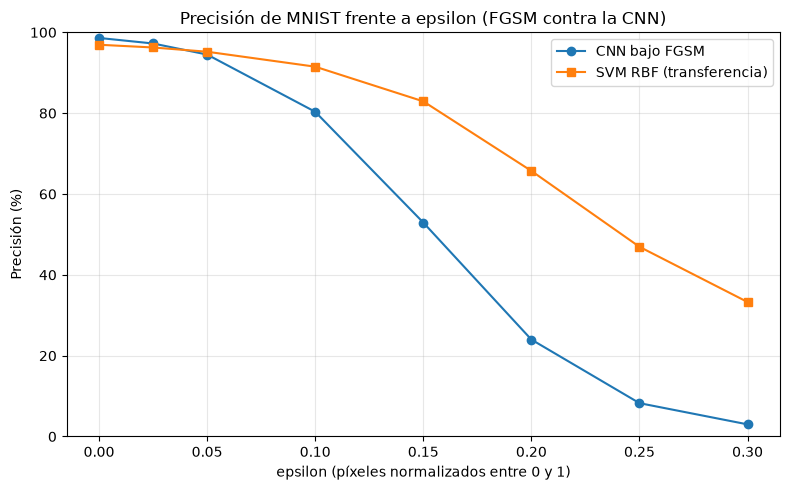

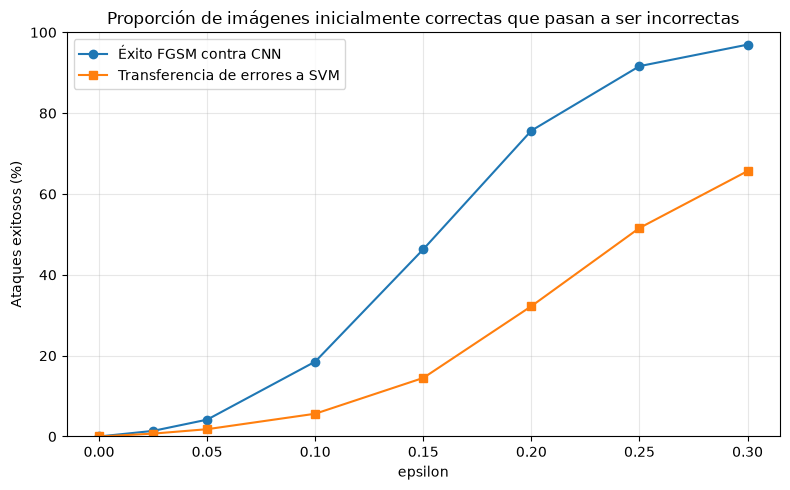

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(resultados["epsilon"], resultados["cnn_adv_pct"], marker="o", label="CNN bajo FGSM")
ax.plot(resultados["epsilon"], resultados["svm_adv_pct"], marker="s", label="SVM RBF (transferencia)")
ax.set(title="Precisión de MNIST frente a epsilon (FGSM contra la CNN)",
       xlabel="epsilon (píxeles normalizados entre 0 y 1)", ylabel="Precisión (%)")
ax.set_ylim(0, 100)
ax.grid(alpha=.3)
ax.legend()
fig.tight_layout()
fig.savefig(CARPETA_SALIDAS / f"precision_vs_epsilon_{MODO}.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(resultados["epsilon"], resultados["exito_fgsm_cnn_pct"], marker="o", label="Éxito FGSM contra CNN")
ax.plot(resultados["epsilon"], resultados["transferencia_svm_pct"], marker="s", label="Transferencia de errores a SVM")
ax.set(title="Proporción de imágenes inicialmente correctas que pasan a ser incorrectas",
       xlabel="epsilon", ylabel="Ataques exitosos (%)")
ax.set_ylim(0, 100)
ax.grid(alpha=.3)
ax.legend()
fig.tight_layout()
fig.savefig(CARPETA_SALIDAS / f"exito_vs_epsilon_{MODO}.png", dpi=180)
plt.show()


## 4. Elegir epsilon y visualizar originales y adversarias

**No hay un epsilon universalmente perfecto.** Elige un valor observando la tabla y las gráficas: queremos cambios de clasificación con perturbaciones que no destruyan la identidad visual del dígito. Para visualizar utilizamos un valor de ejemplo (`EPSILON_VISUAL=0.15`) que puedes modificar después de ver las gráficas.

Seleccionamos varios ejemplos que la CNN clasificaba bien originalmente; damos prioridad a aquellos en los que el ataque sí la engaña. Mostramos predicción original/adversaria de ambos modelos y la etiqueta verdadera.

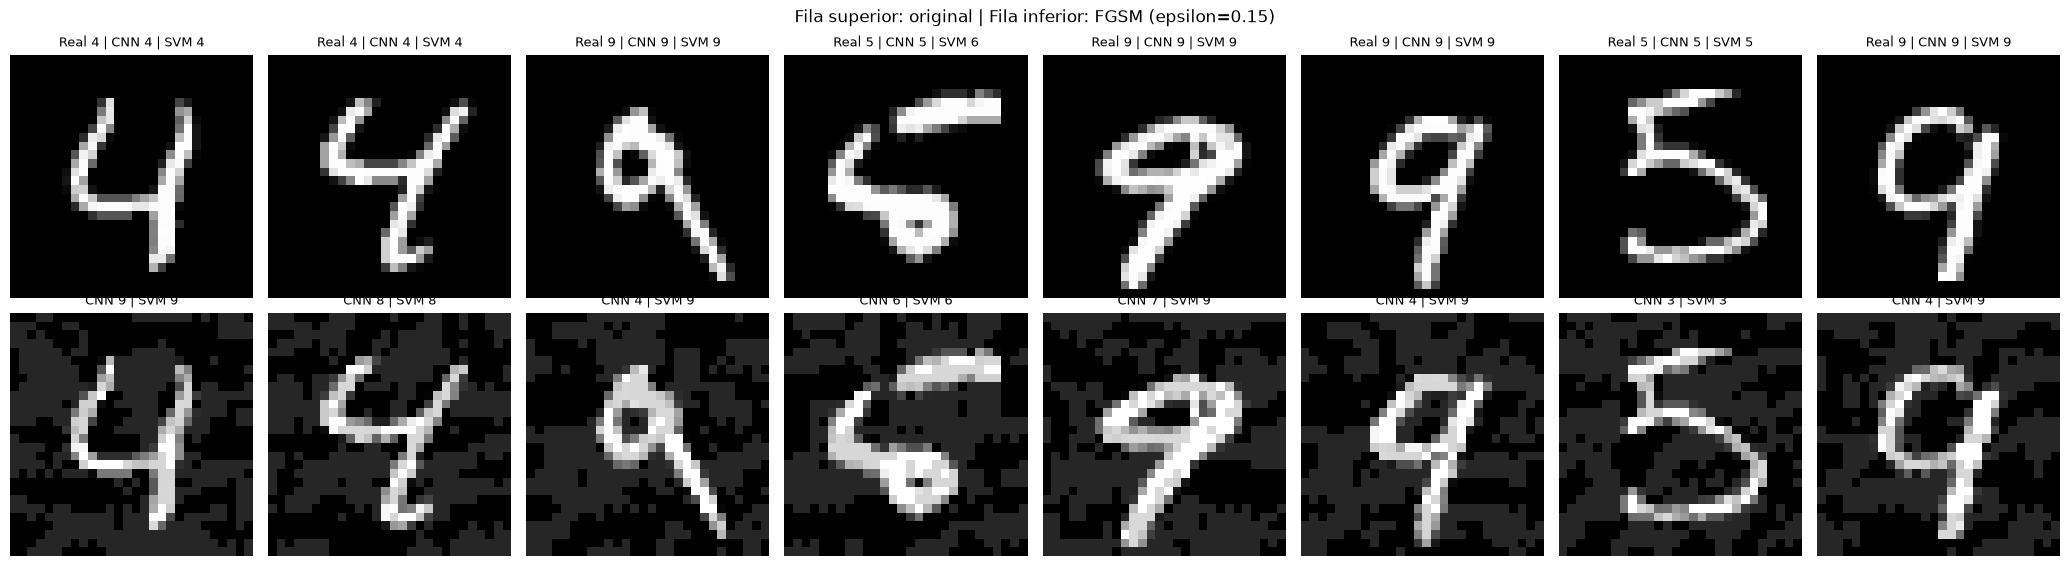

Imagen guardada: /home/laura/proyectos/io_parte2/resultados/originales_y_adversarias_eps_0_15.png


In [12]:
EPSILON_VISUAL = 0.15  # Puedes sustituirlo por el valor que justifiques con los resultados.
NUM_MOSTRAR = 8

candidatos = []
for imagenes, etiquetas in cargador:
    x_adv = ataque_fgsm(cnn, imagenes, etiquetas, EPSILON_VISUAL)
    with torch.no_grad():
        p_cnn = cnn(imagenes).argmax(1).numpy()
        p_cnn_adv = cnn(x_adv).argmax(1).numpy()
    p_svm = svm.predict(imagenes.numpy().reshape(len(imagenes), 784))
    p_svm_adv = svm.predict(x_adv.numpy().reshape(len(x_adv), 784))
    for i in range(len(etiquetas)):
        real = int(etiquetas[i].item())
        if p_cnn[i] != real:
            continue  # Solo mostramos imágenes correctamente clasificadas antes del ataque.
        cambio = int(p_cnn_adv[i] != real)
        candidatos.append((cambio, imagenes[i, 0].numpy(), x_adv[i, 0].numpy(),
                           real, int(p_cnn[i]), int(p_cnn_adv[i]),
                           int(p_svm[i]), int(p_svm_adv[i])))
    # En modo completo se muestran ejemplos de los primeros lotes para evitar repetir todo el test.
    if len(candidatos) >= 300:
        break

candidatos.sort(key=lambda registro: registro[0], reverse=True)
seleccion = candidatos[:NUM_MOSTRAR]
if not seleccion:
    raise RuntimeError("No se encontraron ejemplos inicialmente correctos para visualizar.")

fig, ejes = plt.subplots(2, len(seleccion), figsize=(2.6 * len(seleccion), 5.8), squeeze=False)
for j, (_, x, adv, real, p_cnn, p_cnn_adv, p_svm, p_svm_adv) in enumerate(seleccion):
    ejes[0, j].imshow(x, cmap="gray", vmin=0, vmax=1)
    ejes[1, j].imshow(adv, cmap="gray", vmin=0, vmax=1)
    ejes[0, j].set_title(f"Real {real} | CNN {p_cnn} | SVM {p_svm}", fontsize=9)
    ejes[1, j].set_title(f"CNN {p_cnn_adv} | SVM {p_svm_adv}", fontsize=9)
    for fila in range(2):
        ejes[fila, j].axis("off")
fig.suptitle(f"Fila superior: original | Fila inferior: FGSM (epsilon={EPSILON_VISUAL})", fontsize=12)
fig.tight_layout()
archivo = CARPETA_SALIDAS / f"originales_y_adversarias_eps_{str(EPSILON_VISUAL).replace('.', '_')}.png"
fig.savefig(archivo, dpi=180)
plt.show()
print(f"Imagen guardada: {archivo}")


## 5. Interpretación para la práctica

Completa esta interpretación **después de ejecutar las celdas**, con los valores reales que aparezcan:

- La CNN obtuvo una precisión inicial de `... %` en las imágenes evaluadas.
- La SVM obtuvo una precisión inicial de `... %` sobre esas mismas imágenes.
- Con `epsilon=...`, la precisión de la CNN descendió a `... %`.
- El éxito de FGSM entre las imágenes inicialmente correctas de la CNN fue `... %`.
- La SVM alcanzó `... %` sobre imágenes generadas para atacar **la CNN**: esta diferencia ilustra la **transferencia**, no un ataque específico a la SVM.
- Elegimos `epsilon=...` para las imágenes ilustrativas porque `...`.

**Aspectos metodológicos:** la SVM fue entrenada con 12.000 imágenes de MNIST y la CNN con 60.000; la comparación muestra su comportamiento real, pero no implica igualdad de datos de entrenamiento. Ambas se evalúan aquí sobre los mismos ejemplos de test. Los ejemplos visuales priorizan ataques exitosos y **no representan** la tasa de éxito general: esa se informa con la evaluación completa.

**Apartados opcionales 5–7:** este notebook cubre el apartado 4 y prepara las métricas para extenderlo, pero **no** implementa aún entrenamiento adversario ni ataques dobles. Antes de abordar esos extras, termina y documenta bien los cuatro apartados obligatorios.